# QuaRK: A Quantum Reservoir Kernel for Time Series Learning — reproduction notebook

Paper: A. Aaraba, S. Cherkaoui, O. Ahmad, S. Wang, [arXiv:2602.13531](https://arxiv.org/abs/2602.13531) (2026); authors' code and data: [abdo-aary/quark](https://github.com/abdo-aary/quark). The live cells take about 3 minutes on one CPU and need the authors' release under `data/QuaRK/` (README, section Data); the full results, 100 runs over 5 seeds, are read from `results/`.

The five messages, as in the README:
1. Our run at the authors' seed matches their published run (section 7).
2. Every classical baseline has a lower test error than QuaRK (section 8).
3. Shot noise inflates QuaRK's error, and the paper's figures use the milder noise model (section 10).
4. The paper's learning claims hold only in part (section 7b).
5. A photonic version of the reservoir matches QuaRK, with or without photon interference (section 11).

## 1. Problem and claim

QuaRK learns a scalar label from a window of a time series (25 steps, 3 dimensions) with a fixed random quantum reservoir, read out by a Matérn kernel ridge regression (section 3). The paper's claims (Sec. 4 and Theorem 2):
- **Interpolation:** relaxing the ridge $\lambda_{reg}$ drives the training MSE to numerical zero (Figs. 2 and 3).
- **Decay with N:** the test MSE falls as the number N of training windows grows, with the same $1/\sqrt{N}$ shape for the three tasks (Fig. 4).
- **Task ranking:** F1 < F2 < F3 in test MSE, mirroring how hard the labels are.
- **Generalization bound** for windows drawn from a β-mixing process (Theorem 2).

The paper reports no baseline, no seeds and no error bars.

**Research question:** do these claims hold over several draws of the data, and are they specific to the quantum reservoir? They weaken if a classical model given the same windows, readout and data reaches a lower test MSE or behaves the same way, or if the measured decay excludes $1/\sqrt{N}$.

## 2. Data, splits, metrics and protocol

- **Data:** synthetic, as in the paper: 10,000 windows of a 3-dimensional VARMA(3,3) process passed through tanh. `lib/data.py` replays the authors' generator; seed 12345 is their released dataset, seeds 1–4 are new draws.
- **Labels:** F1 $= u\cdot x_t$, the last point (as in the authors' code; the paper's text calls F1 a one-step forecast, $u\cdot x_{t+1}$, which we run as a fourth task); F2 $= \sum_k 0.8^k\, u\cdot x_{t-k}$; F3 adds $\tfrac12 \big(\sum_k 0.8^k\, v\cdot x_{t-k}\big)^2$ with $v \perp u$.
- **Splits:** the authors' 8,000 training and 2,000 test windows. The kernel and $\lambda_{reg}$ are chosen on validation data, the inner 20 % of the training windows; the test windows only report the error.
- **Metric:** test MSE, and the normalized test MSE (divided by the variance of the test labels) to compare tasks.
- **Comparisons:** paired over 5 seeds; a model is lower when the mean difference exceeds twice its standard error (a rule fixed before the runs). We add the seed count and the 95 % interval of the difference.
- **Deviations:** where the paper's text and code disagree, we follow the code, which produced the figures (README, Reproduction Scope). The authors' test-set choice of $\lambda_{reg}$ is used only to match Fig. 4. The density matrix is simulated in numpy instead of the authors' 11-qubit circuit (checked in section 4).

In [1]:
import sys
import time
from pathlib import Path

START = time.perf_counter()
PAPER = Path.cwd()
assert (PAPER / "lib" / "runner.py").is_file(), "run this notebook from papers/QuaRK"
for path in (
    PAPER.parents[1],
    PAPER.parent,
    PAPER / "utils",
):  # runtime_lib, QuaRK, utils
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

In [2]:
import json
import tempfile
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from scipy.spatial.distance import cdist
from sklearn.gaussian_process.kernels import Matern

from runtime_lib.config import deep_update, load_config
from runtime_lib.data_paths import resolve_data_root
from runtime_lib.dtypes import resolve_config_dtypes

from QuaRK.lib.data import check_against_release, generate_dataset
from QuaRK.lib.kernel_ridge import matern_from_distances
from QuaRK.lib.measurement import k_local_paulis, pauli_features
from QuaRK.lib.quark_merlin import mixture_weights
from QuaRK.lib.reservoir import draw_reservoir_parameters, reservoir_states
from QuaRK.lib.runner import train_and_evaluate
from compare_photonic_with_quark import DETECTION
from plot_style import TASK_LABELS, apply_style
from report_statistics import describe, paired

%matplotlib inline
apply_style()
TASKS = {"current_point_readout": "F1", "exp_fading": "F2", "volterra": "F3"}
RELEASE_RUN = "QuaRK/authors_release_v1.0.0/storage/results/reg_sweep/c-shadows/full/N=10000__w=25__d=3__s=100/2026-02-02_14-02-13"
STORED = {
    name: json.loads((PAPER / "results" / f"{name}.json").read_text())
    for name in ("result_tables", "release_comparison", "statistics", "fair_comparison")
}


def config(overlay=None, changes=None):
    # Defaults, then a named config, then dotted overrides, as the shared runtime merges them.
    cfg = load_config(PAPER / "configs" / "defaults.json")
    if overlay:
        cfg = deep_update(cfg, load_config(PAPER / "configs" / overlay))
    for dotted, value in (changes or {}).items():
        *parents, key = dotted.split(".")
        node = cfg
        for part in parents:
            node = node[part]
        node[key] = value
    return resolve_config_dtypes(cfg)


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


cfg = config("quark_original.json")
data = generate_dataset(cfg["data"], seed=12345)
check = check_against_release(data, cfg["data"], None)
print(
    f"windows {data.windows.shape}: training {len(data.train_idx)}, test {len(data.test_idx)}"
)
print(
    "largest difference with the authors' released dataset: "
    f"windows {check['max_abs_diff_windows']:.1e}, labels {check['max_abs_diff_labels']:.1e}"
)
table(
    ["Task", "Label", "Variance of the test labels"],
    [
        [
            TASKS.get(name, "F1 as written"),
            TASK_LABELS[name],
            f"{np.var(data.labels[i, data.test_idx]):.3f}",
        ]
        for i, name in enumerate(data.task_names)
    ],
)

windows (10000, 25, 3): training 8000, test 2000
largest difference with the authors' released dataset: windows 6.7e-16, labels 4.0e-15


| Task | Label | Variance of the test labels |
|---|---|---|
| F1 | Current-point readout (F1 as run) | 0.488 |
| F2 | Exponential fading (F2) | 0.940 |
| F3 | Volterra (F3) | 1.191 |
| F1 as written | One-step forecast (F1 as written) | 0.478 |

## 3. The method in equations

Each of the 3 sub-reservoirs starts in $|+\rangle\langle+|^{\otimes 5}$. At step $t$, the input is projected, $z_t = x_t\Pi$ (a random $3\times5$ matrix), encoded by $R_y(\theta_t)$ with $\theta_t = \pi(1-10^{-6})\tanh z_t$, mixed by a fixed random Ising unitary $W_r$, and partly reset:

$$\rho \leftarrow \lambda_r\, W_r R_y(\theta_t)\, \rho\, R_y(\theta_t)^\dagger W_r^\dagger + (1-\lambda_r)\, |+\rangle\langle+|^{\otimes 5}.$$

The features are $\phi_P = \mathrm{Tr}(P\rho_{25})$ for the 15 one-qubit and 90 two-qubit Pauli strings: 105 per sub-reservoir, 315 in all, estimated from 1000 shots. The readout solves $\alpha = (K + \lambda_{reg} I)^{-1} y$ with the Matérn kernel $K_{ij} = k_\nu(\lVert\phi_i-\phi_j\rVert/\xi)$ and predicts $k(\phi)^\top\alpha$.

Since the reset returns to the starting state, the final state is a mixture over memory lengths: with weight $(1-\lambda_r)\lambda_r^{\,j}$ ($j<25$) or $\lambda_r^{25}$, only the last $j$ steps acted. The photonic version is built on this identity (section 11).

## 4. Checks with known answers

Three components against an independent answer: the Matérn kernel against scikit-learn's, the reset against the mixture over memory lengths, and our features against those the authors released (10,000 windows at their seed, with their shot noise). These checks validate components, not the end-to-end reproduction.

In [3]:
points = np.random.default_rng(0).normal(size=(50, 6))
kernel_gap = max(
    np.abs(
        matern_from_distances(cdist(points, points), 1.7, nu)
        - Matern(length_scale=1.7, nu=nu)(points)
    ).max()
    for nu in (0.5, 1.5, 2.5, 5.0)
)

quark = cfg["model"]["quark"]
params = draw_reservoir_parameters(
    input_dim=3,
    num_qubits=quark["num_qubits"],
    num_reservoirs=quark["num_reservoirs"],
    first_contraction=quark["first_contraction"],
    seed=12345,
)
sample, steps = data.windows[:20], data.windows.shape[1]
sequential = reservoir_states(sample, params)
no_reset = replace(params, contractions=np.ones_like(params.contractions))
last_steps = np.stack(
    [reservoir_states(sample[:, steps - j :], no_reset) for j in range(steps + 1)]
)
weights = np.stack([mixture_weights(lam, steps) for lam in params.contractions])
mixture_gap = np.abs(
    np.einsum("rj,jnrab->nrab", weights, last_steps) - sequential
).max()

states = reservoir_states(data.windows, params)
features = pauli_features(
    states,
    locality=quark["locality"],
    estimator=quark["estimator"],
    shots=quark["shots"],
    seed=12345,
)
released = np.load(resolve_data_root(None) / RELEASE_RUN / "model" / "arrays.npz")[
    "Phi_full"
]
table(
    ["Check", "Largest difference"],
    [
        [
            "Matérn kernel against scikit-learn (ν = 0.5, 1.5, 2.5, 5)",
            f"{kernel_gap:.1e}",
        ],
        [
            "Reset channel against the mixture over memory lengths (20 windows)",
            f"{mixture_gap:.1e}",
        ],
        [
            f"Our features against the authors' released features ({features.shape[0]:,} × {features.shape[1]})",
            f"{np.abs(features - released).max():.1e}",
        ],
    ],
)

| Check | Largest difference |
|---|---|
| Matérn kernel against scikit-learn (ν = 0.5, 1.5, 2.5, 5) | 5.6e-16 |
| Reset channel against the mixture over memory lengths (20 windows) | 6.9e-17 |
| Our features against the authors' released features (10,000 × 315) | 0.0e+00 |

All three agree to rounding error, our features exactly, as does the dataset (section 2): every later result rests on the authors' own computation.

## 5. The pipeline, step by step

The reservoir's settings, its random draws at the authors' seed, and the fading memory that the reset creates: flipping one input step moves the final features less, the older the step.

QuaRK settings: {'num_qubits': 5, 'num_reservoirs': 3, 'locality': 2, 'first_contraction': 0.1, 'estimator': 'per_observable_shots', 'shots': 1000}
contractions λ_r of the three sub-reservoirs: [0.1   0.34  0.259]
105 Pauli observables per sub-reservoir; feature matrix (10000, 315)


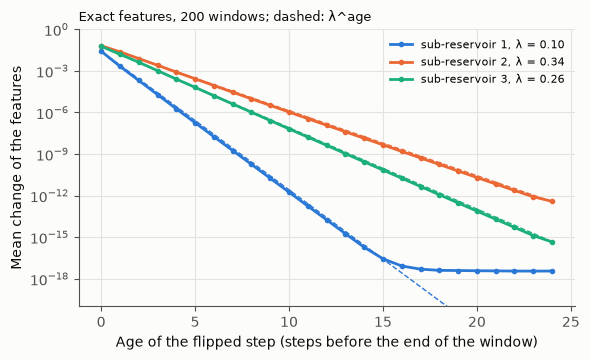

In [4]:
print("QuaRK settings:", quark)
print("contractions λ_r of the three sub-reservoirs:", np.round(params.contractions, 3))
print(
    f"{len(k_local_paulis(quark['locality'], quark['num_qubits']))} Pauli observables per sub-reservoir; feature matrix {features.shape}"
)

probe = data.windows[:200]
reference = pauli_features(
    reservoir_states(probe, params), locality=2, estimator="exact", shots=0, seed=0
)
change = np.empty((steps, params.contractions.size))
for t in range(steps):
    flipped = probe.copy()
    flipped[:, t] *= -1
    moved = pauli_features(
        reservoir_states(flipped, params),
        locality=2,
        estimator="exact",
        shots=0,
        seed=0,
    )
    change[t] = (
        np.abs(moved - reference)
        .reshape(len(probe), params.contractions.size, -1)
        .mean(axis=(0, 2))
    )

age = steps - 1 - np.arange(steps)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for r, (lam, color) in enumerate(
    zip(params.contractions, ("#2a78d6", "#eb6834", "#1baf7a"))
):
    ax.plot(
        age,
        change[:, r],
        marker="o",
        ms=3,
        color=color,
        label=f"sub-reservoir {r + 1}, λ = {lam:.2f}",
    )
    ax.plot(age, change[-1, r] * lam**age, ls="--", lw=1, color=color)
ax.set(
    yscale="log",
    ylim=(1e-20, 1),
    xlabel="Age of the flipped step (steps before the end of the window)",
    ylabel="Mean change of the features",
)
ax.set_title("Exact features, 200 windows; dashed: λ^age", loc="left", fontsize=9)
ax.legend(frameon=False, fontsize=8)
plt.show()

The change falls exactly as $\lambda_r^{\,\mathrm{age}}$ (dashed) down to floating-point precision: a step $k$ steps old moves the features $\lambda_r^k$ as much as the newest one, so after 10 steps $10^{-10}$ as much in sub-reservoir 1. This fading memory is the contraction that the paper's analysis relies on.

## 6. A small live experiment

A reduced main comparison through the reproduction's own runner: 1,000 windows instead of 10,000, three seeds instead of five, the three paper tasks. Models: QuaRK at the paper's settings and with exact expectations; the untuned echo state network (ESN), a fixed random classical reservoir with 315 units, as many as QuaRK's features, and the same readout; the Matérn kernel on the raw window.

In [5]:
LIVE_MODELS = {
    "QuaRK (paper settings)": "quark_original.json",
    "QuaRK, exact expectations": "quark_exact_original.json",
    "Echo state network, default": "esn_default_classical.json",
    "Matérn kernel on the raw window": "raw_window_kernel_classical.json",
}
LIVE_SEEDS = (12345, 1, 2)
LIVE_CHANGES = {
    "data.num_windows": 1000,
    "data.check_release": False,
    "data.tasks": list(TASKS),
    "outputs.save_features": False,
}


def live_run(overlay, seed):
    run_cfg = config(overlay, {**LIVE_CHANGES, "seed": seed})
    with tempfile.TemporaryDirectory() as run_dir:
        train_and_evaluate(run_cfg, Path(run_dir))
        return json.loads((Path(run_dir) / "metrics.json").read_text())["tasks"]


def live_value(runs, name, seed, task):
    return runs[(name, seed)][task]["selections"]["validation"]["normalized_mse_test"]


live = {
    (name, seed): live_run(overlay, seed)
    for name, overlay in LIVE_MODELS.items()
    for seed in LIVE_SEEDS
}
table(
    ["Model", *(f"{short}, seeds 12345 / 1 / 2" for short in TASKS.values())],
    [
        [
            name,
            *(
                " / ".join(f"{live_value(live, name, s, task):.3g}" for s in LIVE_SEEDS)
                for task in TASKS
            ),
        ]
        for name in LIVE_MODELS
    ],
)
print("Normalized test MSE, λ_reg chosen on validation data.")

| Model | F1, seeds 12345 / 1 / 2 | F2, seeds 12345 / 1 / 2 | F3, seeds 12345 / 1 / 2 |
|---|---|---|---|
| QuaRK (paper settings) | 0.0259 / 0.0125 / 0.0477 | 0.621 / 0.383 / 0.454 | 0.63 / 0.608 / 0.603 |
| QuaRK, exact expectations | 0.00122 / 0.000122 / 0.00171 | 0.491 / 0.268 / 0.287 | 0.493 / 0.476 / 0.542 |
| Echo state network, default | 0.000975 / 0.00109 / 0.000952 | 0.077 / 0.0827 / 0.0523 | 0.181 / 0.179 / 0.191 |
| Matérn kernel on the raw window | 1.27e-08 / 1.72e-08 / 1.44e-08 | 1.74e-08 / 9.22e-09 / 5.97e-09 | 0.231 / 0.247 / 0.288 |

Normalized test MSE, λ_reg chosen on validation data.


**Observation:** the untuned ESN has a lower test MSE than QuaRK in every seed on the three tasks, and than QuaRK with exact expectations on F2 and F3 (on F1 these two are close). The raw-window kernel fits F1 and F2 almost exactly but trails the ESN on F3.
**Inference:** the order between the quantum and the classical reservoir already shows with 800 training windows.
**Remaining uncertainty:** 3 seeds and 1,000 windows; the stored full runs decide (sections 7 to 10). With 8,000 training windows, the raw-window kernel reaches $7\cdot10^{-5}$ on F3.
**Claim impact:** none alone; it previews message 2.

## 7. Headline result: our run at the authors' seed matches their published run

**Scope:** faithful reproduction at the paper's settings and the authors' seed, with their test-set choice of $\lambda_{reg}$ for Fig. 4.

**Stored full results:** 4 sweeps, 100 runs at 10,000 windows and 5 seeds, all completed and validated at the first attempt; code commit `28af1fb` with the working tree recorded per run; Python 3.14.2, numpy 2.5.4, merlinquantum 0.4.2; one CPU (Apple M5), 9 to 17 minutes per run. The `utils/` scripts listed in the README write the `results/` files read here.

| Quantity (release / ours) | F1 | F2 | F3 |
|---|---|---|---|
| Kernel ν, release / ours | 5 / 5 | 0.5 / 0.5 | 0.5 / 0.5 |
| Kernel ξ, release / ours | 17.495639 / 17.495639 | 17.016439 / 17.016439 | 15.391541 / 15.391541 |
| Fig. 2, training MSE at λ_reg = 10⁵ | 0.4736 / 0.4736 | 0.9378 / 0.9378 | 1.269 / 1.269 |
| Fig. 4, test MSE at N = 100 | 0.08882 / 0.08882 | 0.7153 / 0.7153 | 0.9361 / 0.9361 |
| Fig. 4, test MSE at N = 8000 | 0.004306 / 0.004306 | 0.4491 / 0.4491 | 0.6508 / 0.6508 |
| Largest relative difference (ξ, Figs. 2 and 4) | 4.6e-10 | 2.5e-10 | 1.4e-09 |

Stored sweeps: Main comparison 35/35 runs, COMPLETE SWEEP; Shot budget 20/20 runs, COMPLETE SWEEP; Reservoir size 20/20 runs, COMPLETE SWEEP; Photonic adaptation 25/25 runs, COMPLETE SWEEP


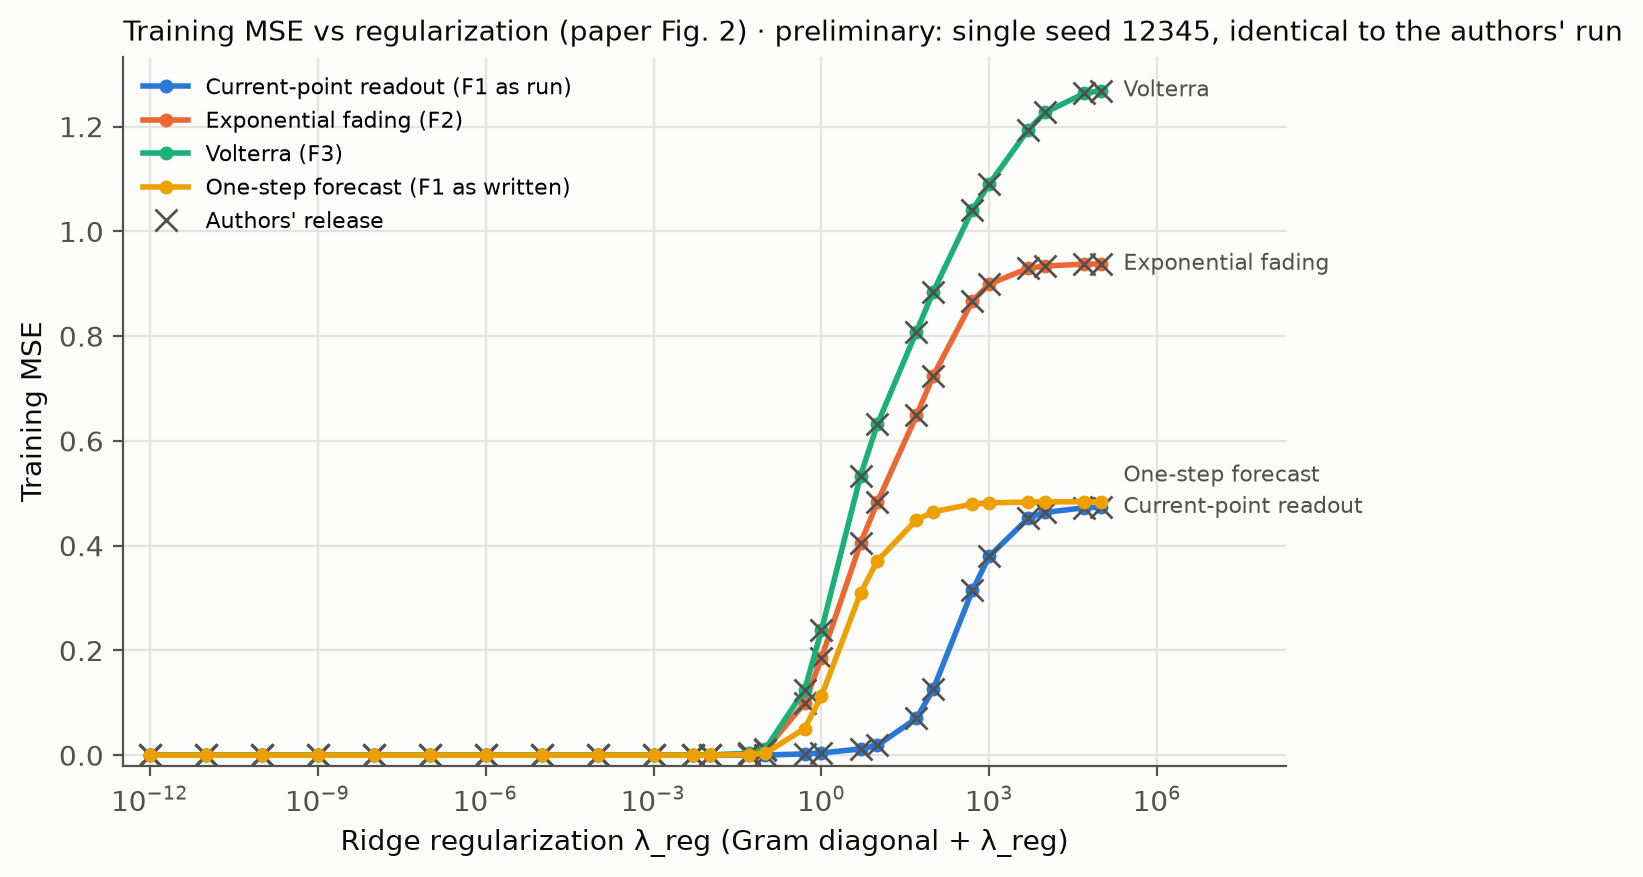

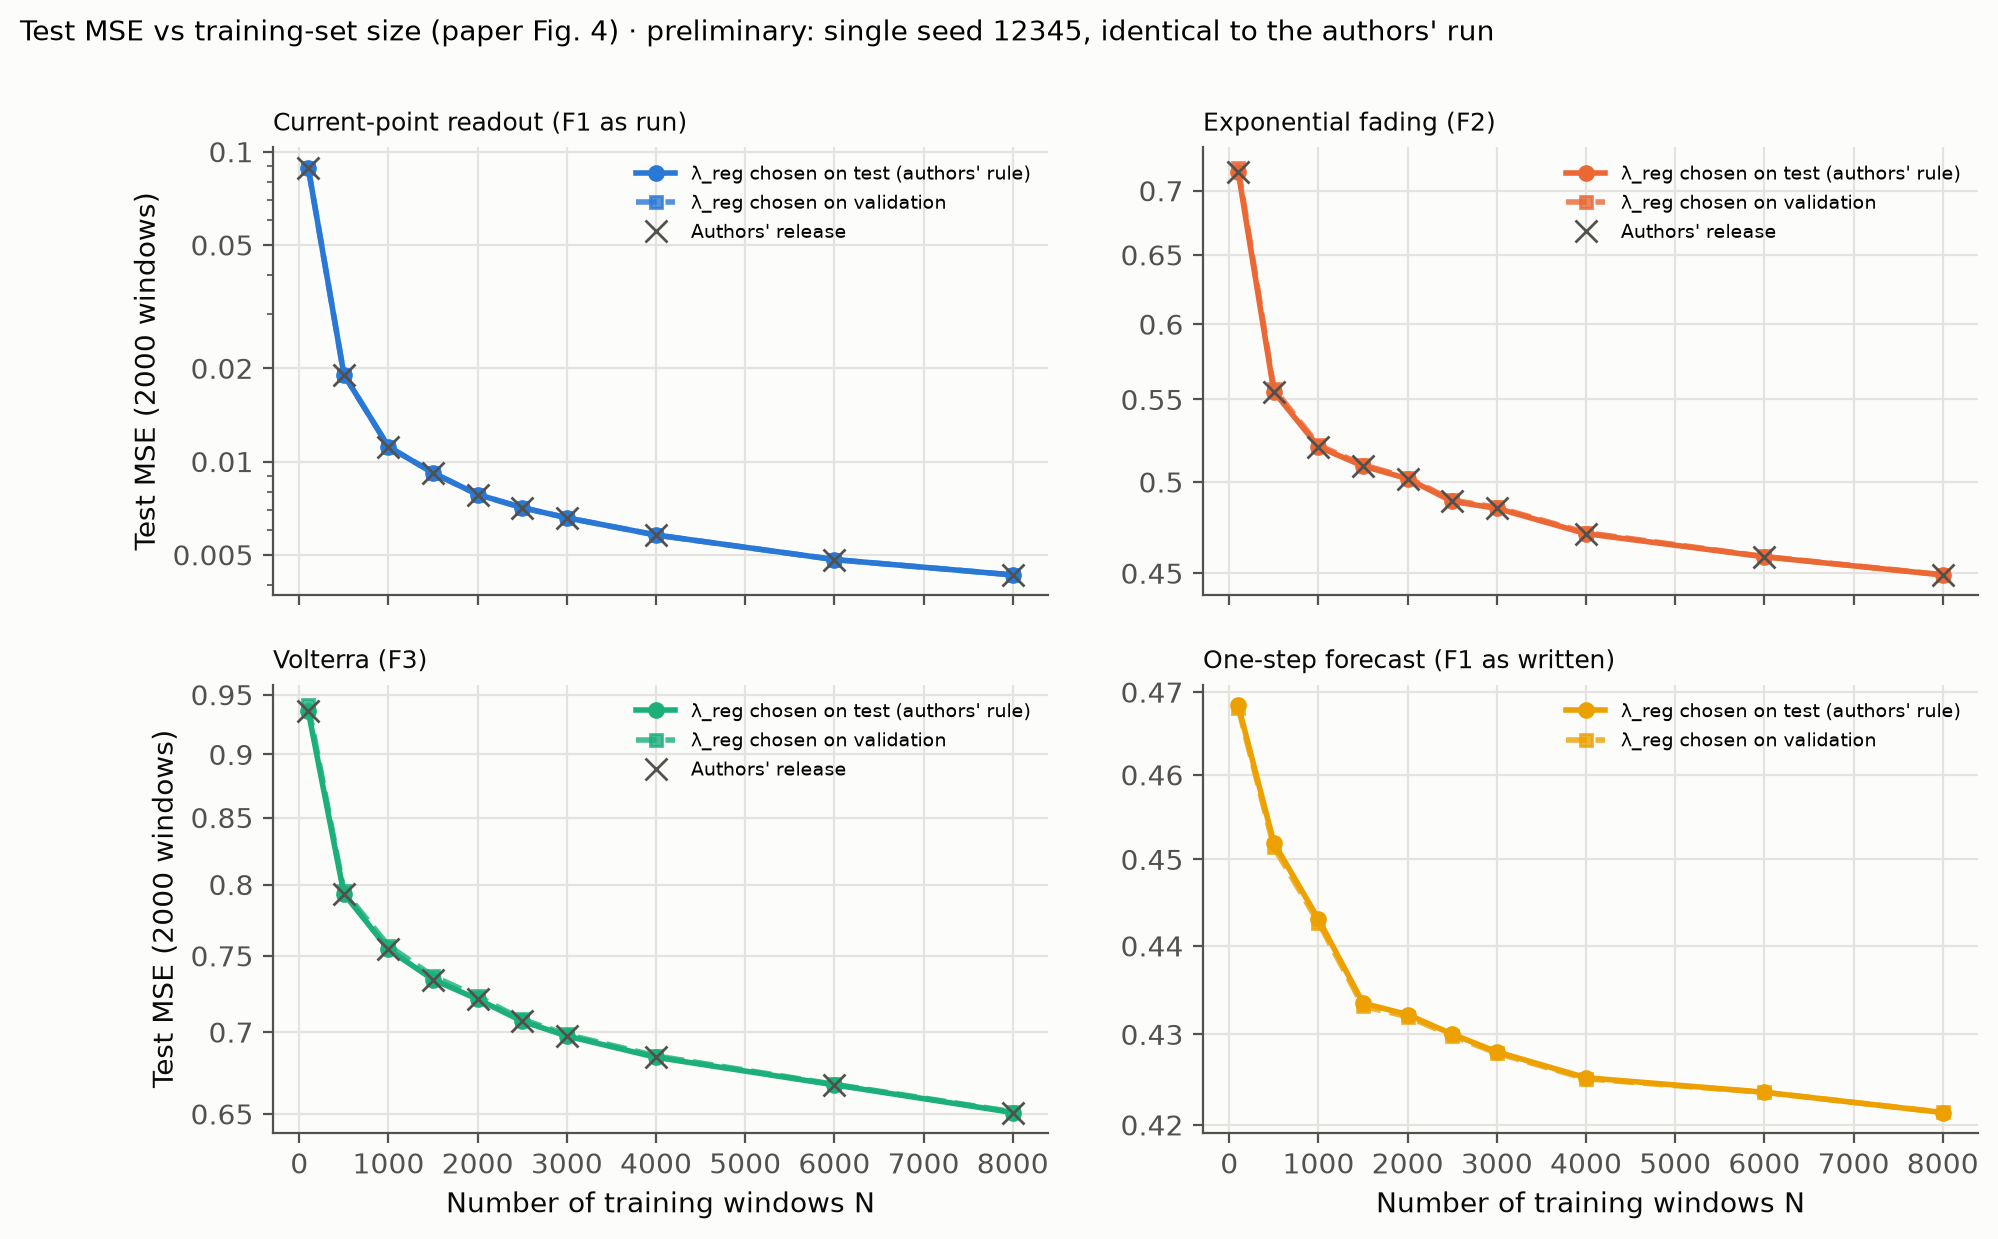

In [6]:
release = STORED["release_comparison"]["tasks"]


def both(task, key, digits):
    pair = release[task][key]
    return f"{pair['release']:.{digits}g} / {pair['ours']:.{digits}g}"


rows = [
    ["Kernel ν, release / ours", *(both(t, "nu", 3) for t in TASKS)],
    ["Kernel ξ, release / ours", *(both(t, "xi", 8) for t in TASKS)],
    [
        "Fig. 2, training MSE at λ_reg = 10⁵",
        *(both(t, "fig2_training_mse_at_largest_ridge", 4) for t in TASKS),
    ],
    [
        "Fig. 4, test MSE at N = 100",
        *(
            f"{release[t]['fig4_test_mse_first_last']['release'][0]:.4g} / {release[t]['fig4_test_mse_first_last']['ours'][0]:.4g}"
            for t in TASKS
        ),
    ],
    [
        "Fig. 4, test MSE at N = 8000",
        *(
            f"{release[t]['fig4_test_mse_first_last']['release'][1]:.4g} / {release[t]['fig4_test_mse_first_last']['ours'][1]:.4g}"
            for t in TASKS
        ),
    ],
    [
        "Largest relative difference (ξ, Figs. 2 and 4)",
        *(
            f"{max(release[t][k] for k in ('xi_relative_difference', 'fig2_training_mse_max_relative_difference_above_rounding_level', 'fig2_test_mse_max_relative_difference', 'fig4_test_mse_max_relative_difference')):.1e}"
            for t in TASKS
        ),
    ],
]
table(["Quantity (release / ours)", *TASKS.values()], rows)
print(
    "Stored sweeps: "
    + "; ".join(
        f"{s['title']} {s['completed_runs']}/{s['expected_runs']} runs, {s['coverage']}"
        for s in STORED["result_tables"]["sweeps"].values()
    )
)
display(
    Image(filename=str(PAPER / "results" / "fig2_regularization_sweep.png"), width=760)
)
display(
    Image(filename=str(PAPER / "results" / "fig4_training_size_sweep.png"), width=760)
)

**Observation:** the kernels, Fig. 2 and Fig. 4 agree with the release within $1.5\cdot10^{-9}$; the crosses (release) sit on our curves.
**Inference:** with the identical features of section 4, our implementation is the computation behind the paper's figures.
**Remaining uncertainty:** one draw of the data; section 7b uses five.
**Claim impact:** the paper's figures reproduce.

### 7b. The paper's learning claims hold only in part

**Scope:** paper-accurate settings, 5 seeds, $\lambda_{reg}$ chosen on validation data; one line per seed.

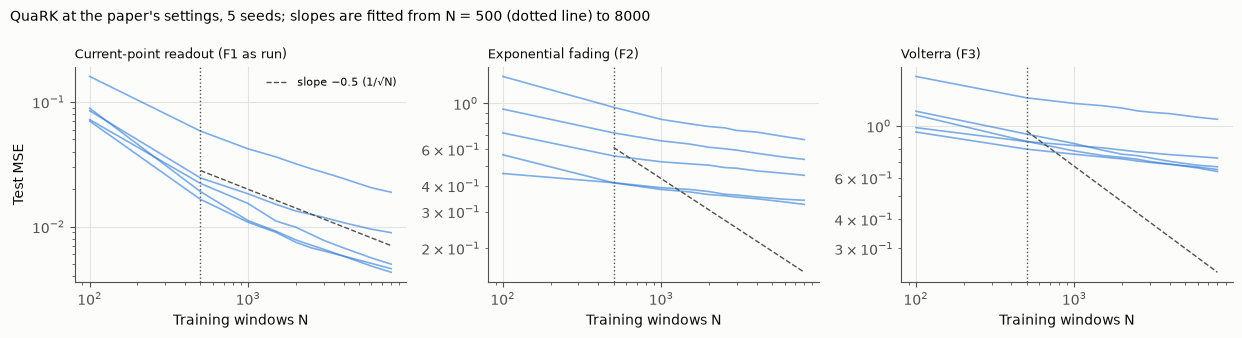

| Claim | Measured (5 seeds) |
|---|---|
| Interpolation: largest training MSE at λ_reg = 10⁻¹² | QuaRK 5.6e-21; its two variants at most 1.1e-11; the classical Matérn-kernel models at most 8.9e-13 |
| Decay with N: slope of log test MSE against log N, mean and 95 % interval | F1 -0.46 (-0.55 to -0.37); F2 -0.09 (-0.12 to -0.07); F3 -0.09 (-0.11 to -0.06) |
| Task ranking F1 < F2 < F3, seeds out of 5 | QuaRK (paper settings) 5; QuaRK, exact expectations 5; QuaRK, random-Pauli shadows 5; Matérn kernel on the raw window 5; Linear ridge on the raw window 5; Echo state network, default 5; Echo state network, tuned 5 |
| Task ranking on normalized test MSE, seeds out of 5 | QuaRK 3 |
| Bound (Theorem 2): its terms over the measured gap, at N = 8000 | F1 6,605 / F2 1,733 / F3 1,427 (at least) |
| Fits with ν ≤ 1, outside Theorem 2's ν > 1 | F1 3/55; F2 25/55; F3 31/55 |

In [7]:
SEEDS = {
    c["candidate"]: c["per_seed"]
    for s in STORED["result_tables"]["sweeps"].values()
    for c in s["candidates"]
}
LABEL = {
    c["candidate"]: c["label"]
    for s in STORED["result_tables"]["sweeps"].values()
    for c in s["candidates"]
}
SIZES = np.array(STORED["result_tables"]["sweeps"]["main"]["training_sizes"])
MAIN = (
    "quark",
    "quark_exact",
    "quark_shadows",
    "raw_window_kernel",
    "raw_window_linear",
    "esn_default",
    "esn_tuned",
)


def values(candidate, task, key="normalized_mse_test"):
    return {
        int(seed): run["tasks"][task][key] for seed, run in SEEDS[candidate].items()
    }


fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, task in zip(axes, TASKS):
    curves = np.array(list(values("quark", task, "training_size_mse_test").values()))
    for curve in curves:
        ax.plot(SIZES, curve, color="#2a78d6", alpha=0.6, lw=1.2)
    anchor = curves[:, SIZES == 500].mean()
    ax.plot(
        SIZES[SIZES >= 500],
        anchor * (SIZES[SIZES >= 500] / 500) ** -0.5,
        color="#52514e",
        ls="--",
        lw=1,
        label="slope −0.5 (1/√N)",
    )
    ax.axvline(500, color="#52514e", ls=":", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="Training windows N")
    ax.set_title(TASK_LABELS[task], loc="left", fontsize=9)
axes[0].set_ylabel("Test MSE")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(
    "QuaRK at the paper's settings, 5 seeds; slopes are fitted from N = 500 (dotted line) to 8000",
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
plt.show()

slopes = {
    task: describe(values("quark", task, "decay_slope").values()) for task in TASKS
}
interpolation = {
    c: max(max(values(c, t, "mse_train_at_smallest_reg").values()) for t in TASKS)
    for c in MAIN
    if c != "raw_window_linear"
}


def ranked(candidate, key):
    per_task = [values(candidate, t, key) for t in TASKS]
    return sum(per_task[0][s] < per_task[1][s] < per_task[2][s] for s in per_task[0])


bound = {
    b["task"]: b["min_ratio_partial_to_gap"]
    for b in STORED["statistics"]["bound"]["paper_settings"]
}
nu = STORED["statistics"]["bound"]["nu_counts_all_quark_runs"]
table(
    ["Claim", "Measured (5 seeds)"],
    [
        [
            "Interpolation: largest training MSE at λ_reg = 10⁻¹²",
            f"QuaRK {interpolation['quark']:.1e}; its two variants at most {max(interpolation[c] for c in MAIN[1:3]):.1e}; the classical Matérn-kernel models at most {max(interpolation[c] for c in MAIN[3:] if c in interpolation):.1e}",
        ],
        [
            "Decay with N: slope of log test MSE against log N, mean and 95 % interval",
            "; ".join(
                f"{TASKS[t]} {s['mean']:.2f} ({s['ci95'][0]:.2f} to {s['ci95'][1]:.2f})"
                for t, s in slopes.items()
            ),
        ],
        [
            "Task ranking F1 < F2 < F3, seeds out of 5",
            "; ".join(f"{LABEL[c]} {ranked(c, 'mse_test')}" for c in MAIN),
        ],
        [
            "Task ranking on normalized test MSE, seeds out of 5",
            f"QuaRK {ranked('quark', 'normalized_mse_test')}",
        ],
        [
            "Bound (Theorem 2): its terms over the measured gap, at N = 8000",
            " / ".join(f"{TASKS[t]} {bound[t]:,.0f}" for t in TASKS) + " (at least)",
        ],
        [
            "Fits with ν ≤ 1, outside Theorem 2's ν > 1",
            "; ".join(
                f"{TASKS[t]} {nu[t]['nu_at_most_one']}/{nu[t]['fits']}" for t in TASKS
            ),
        ],
    ],
)

**Observation:** QuaRK and every classical Matérn-kernel model interpolate. The test MSE falls with N in every seed, but only F1 has a slope compatible with −0.5; F2 and F3 flatten near −0.1. F1 < F2 < F3 holds in every seed for every model, the linear ridge included. The bound's terms exceed the measured gap more than a thousandfold.
**Inference:** interpolation and the ranking come from the kernel readout and the labels (section 9), not from the quantum reservoir.
**Remaining uncertainty:** with an additive floor, any decreasing curve would fit "the same shape"; we test the slope. The proof of Theorem 2 was not re-checked.
**Claim impact:** interpolation and decay reproduce but are not specific to QuaRK; $1/\sqrt{N}$ holds for F1 only; the ranking is explained by the labels; the bound is far from the measured errors.

## 8. Fair baselines: every classical baseline has a lower test error than QuaRK

The paper has no baseline; these four are ours, planned before the runs, on the same windows, split and seeds:

| Dimension | QuaRK | Classical baselines |
|---|---|---|
| Inputs | the window, step by step | ESNs: step by step; kernel and linear ridge: the flattened window (75 numbers) |
| Features | 315 | ESNs: 315 (matched); raw window: 75 |
| Trained parameters | one readout weight per training window | the same for every kernel model; linear ridge: 76; no reservoir is trained |
| Training data | 8,000 windows | the same |
| Optimization | closed-form solves | the same |
| Tuning budget | ν (4 values), ξ (≤ 80 evaluations), $\lambda_{reg}$ (26 values), on validation data | the same; the tuned ESN also picks 1 of 18 reservoir settings, so the untuned ESN is the one matched to QuaRK's untuned reservoir |
| Wall time, one CPU | 10–11 min per run (features: 1–5 % of it) | 10–13 min; linear ridge 4 s |
| Evaluation | test MSE on the same 2,000 windows, same rule | the same |

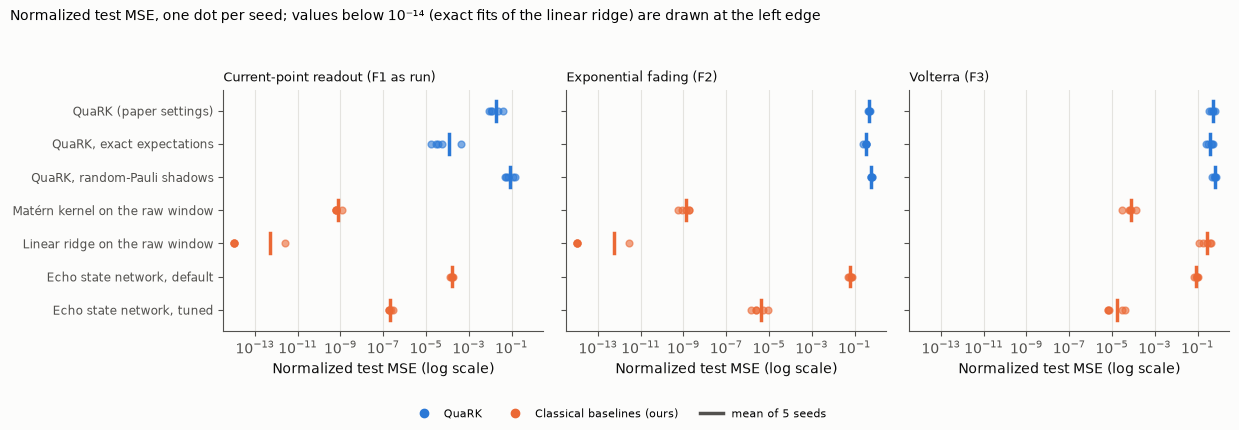

| Model | F1, normalized test MSE | F2, normalized test MSE | F3, normalized test MSE |
|---|---|---|---|
| QuaRK (paper settings) | 0.019 ± 0.013 | 0.48 ± 0.035 | 0.508 ± 0.1 |
| QuaRK, exact expectations | 0.000116 ± 0.00018 | 0.328 ± 0.044 | 0.391 ± 0.11 |
| QuaRK, random-Pauli shadows | 0.0881 ± 0.042 | 0.62 ± 0.026 | 0.634 ± 0.098 |
| Matérn kernel on the raw window | 7.4e-10 ± 2.4e-10 | 1.3e-09 ± 5.8e-10 | 7.37e-05 ± 3.8e-05 |
| Linear ridge on the raw window | 5.03e-13 ± 1.1e-12 | 5.5e-13 ± 1.2e-12 | 0.281 ± 0.13 |
| Echo state network, default | 0.000158 ± 1.6e-05 | 0.0634 ± 0.011 | 0.0895 ± 0.015 |
| Echo state network, tuned | 2.07e-07 ± 4.3e-08 | 4.2e-06 ± 3e-06 | 1.8e-05 ± 1.6e-05 |

| QuaRK | Baseline | F1 | F2 | F3 |
|---|---|---|---|---|
| QuaRK (paper settings) | Matérn kernel on the raw window | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK (paper settings) | Linear ridge on the raw window | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK (paper settings) | Echo state network, default | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK (paper settings) | Echo state network, tuned | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK, exact expectations | Matérn kernel on the raw window | not separated | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK, exact expectations | Linear ridge on the raw window | not separated | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK, exact expectations | Echo state network, default | not separated | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |
| QuaRK, exact expectations | Echo state network, tuned | not separated | baseline lower, 5/5 seeds | baseline lower, 5/5 seeds |

In [8]:
FAMILY_COLOR = {"quantum": "#2a78d6", "photonic": "#1baf7a", "classical": "#eb6834"}
FAMILY_LABEL = {
    "quantum": "QuaRK",
    "photonic": "Photonic adaptation (ours, simulated)",
    "classical": "Classical baselines (ours)",
}
FAMILY = {
    **dict.fromkeys(("quark", "quark_exact", "quark_shadows"), "quantum"),
    **dict.fromkeys(MAIN[3:], "classical"),
    **dict.fromkeys(
        ("quark_merlin", "quark_exact_merlin", "quark_distinguishable_merlin"),
        "photonic",
    ),
}
FLOOR = 1e-14


def dot_plot(models, title):
    fig, axes = plt.subplots(
        1, 3, figsize=(12.5, 1.1 + 0.45 * len(models)), sharey=True
    )
    rows = np.arange(len(models))[::-1]
    for ax, task in zip(axes, TASKS):
        for row, candidate in zip(rows, models):
            v = np.array(list(values(candidate, task).values()))
            color = FAMILY_COLOR[FAMILY[candidate]]
            ax.scatter(
                np.maximum(v, FLOOR),
                np.full(v.size, row),
                s=24,
                alpha=0.6,
                color=color,
                zorder=3,
            )
            ax.plot(
                [max(v.mean(), FLOOR)] * 2,
                [row - 0.3, row + 0.3],
                lw=2.5,
                color=color,
                zorder=4,
            )
        ax.set(
            xscale="log", xlim=(FLOOR / 3, 3), xlabel="Normalized test MSE (log scale)"
        )
        ax.set_title(TASK_LABELS[task], loc="left", fontsize=9)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(rows, [LABEL[c] for c in models], fontsize=8.5)
    families = list(dict.fromkeys(FAMILY[c] for c in models))
    handles = [
        plt.Line2D(
            [], [], marker="o", ls="none", color=FAMILY_COLOR[f], label=FAMILY_LABEL[f]
        )
        for f in families
    ]
    handles.append(plt.Line2D([], [], color="#52514e", lw=2.5, label="mean of 5 seeds"))
    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=len(handles),
        frameon=False,
        fontsize=8,
    )
    fig.suptitle(title, x=0.01, ha="left", fontsize=10)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    plt.show()


def compare(a, b, task):
    # The frozen rule, on the test MSE of the shared seeds.
    return paired(values(a, task, "mse_test"), values(b, task, "mse_test"), a, b)


def versus(a, b, task, names=None):
    first, second = names or (LABEL[a], LABEL[b])
    p = compare(a, b, task)
    n = len(p["seeds"])
    if p["label"] == "no clear separation":
        text = "not separated"
    elif p["label"] == f"{a} lower":
        text = f"{first} lower, {p['a_lower_seeds']}/{n} seeds"
    else:
        text = f"{second} lower, {n - p['a_lower_seeds']}/{n} seeds"
    return text + (" (interval contains 0)" if p["flag_interval_contains_zero"] else "")


dot_plot(
    MAIN,
    "Normalized test MSE, one dot per seed; values below 10⁻¹⁴ (exact fits of the linear ridge) are drawn at the left edge",
)
table(
    ["Model", *(f"{s}, normalized test MSE" for s in TASKS.values())],
    [
        [
            LABEL[c],
            *(
                f"{describe(values(c, t).values())['mean']:.3g} ± {describe(values(c, t).values())['std']:.2g}"
                for t in TASKS
            ),
        ]
        for c in MAIN
    ],
)
BASELINES = MAIN[3:]
table(
    ["QuaRK", "Baseline", *TASKS.values()],
    [
        [LABEL[q], LABEL[b], *(versus(q, b, t, ("QuaRK", "baseline")) for t in TASKS)]
        for q in ("quark", "quark_exact")
        for b in BASELINES
    ],
)

**Observation:** every baseline is lower than QuaRK on the three tasks in 5 of 5 seeds, the untuned ESN included (normalized 0.063 and 0.090 on F2 and F3, against 0.48 and 0.51). Without shot noise, QuaRK is still behind every baseline on F2 and F3, and not separated from them on F1.
**Inference:** with the same readout, data and number of features, a random classical reservoir learns these tasks better; the results show no advantage of the quantum features.
**Remaining uncertainty:** one family of synthetic tasks, with 3 input dimensions.
**Claim impact:** the paper states no advantage; an implied one is not supported.

## 9. Controls and ablations

Each control tests another explanation: shot noise as the whole gap, linear labels behind the ranking, interpolation as a property of any Matérn kernel, and the noise floor of the forecast (F1 as the paper's text defines it).

In [9]:
exact_behind = sum(
    compare("quark_exact", b, t)["label"] == f"{b} lower"
    and compare("quark_exact", b, t)["a_lower_seeds"] == 0
    for b in BASELINES
    for t in ("exp_fading", "volterra")
)
linear = max(
    max(values("raw_window_linear", t).values())
    for t in ("current_point_readout", "exp_fading")
)
oracle = STORED["statistics"]["forecast"]["oracle_test_mse_normalized"]
forecast = [describe(values(c, "one_step_forecast").values())["mean"] for c in MAIN]
table(
    ["Control", "Question", "Result"],
    [
        [
            "QuaRK with exact expectations",
            "Is shot noise the only reason QuaRK is behind?",
            f"{exact_behind} of {2 * len(BASELINES)} baseline–task pairs (F2, F3) still lower than QuaRK in 5/5 seeds",
        ],
        [
            "Linear ridge on the raw window",
            "Are F1 and F2 linear in the window?",
            f"normalized test MSE at most {linear:.0e} on F1 and F2",
        ],
        [
            "Matérn kernel on the raw window",
            "Is interpolation specific to quantum features?",
            f"training MSE at most {interpolation['raw_window_kernel']:.0e} at λ_reg = 10⁻¹²",
        ],
        [
            "One-step forecast (F1 as written)",
            "How close is each model to the noise floor?",
            f"oracle (conditional mean given the true past) {oracle['mean']:.2f} ± {oracle['std']:.2f} over the seeds; the 7 models {min(forecast):.2f} to {max(forecast):.2f}",
        ],
    ],
)

| Control | Question | Result |
|---|---|---|
| QuaRK with exact expectations | Is shot noise the only reason QuaRK is behind? | 8 of 8 baseline–task pairs (F2, F3) still lower than QuaRK in 5/5 seeds |
| Linear ridge on the raw window | Are F1 and F2 linear in the window? | normalized test MSE at most 3e-12 on F1 and F2 |
| Matérn kernel on the raw window | Is interpolation specific to quantum features? | training MSE at most 4e-13 at λ_reg = 10⁻¹² |
| One-step forecast (F1 as written) | How close is each model to the noise floor? | oracle (conditional mean given the true past) 0.80 ± 0.10 over the seeds; the 7 models 0.83 to 0.91 |

**Observation:** without shot noise the gap remains (8 of 8 pairs on F2 and F3); a linear ridge fits F1 and F2 to $3\cdot10^{-12}$; a classical Matérn kernel interpolates as QuaRK does; on the forecast, every model lies 0.03 to 0.11 above the oracle.
**Inference:** shot noise is QuaRK's main handicap but not its only one; the ranking reflects how linear each label is; interpolation belongs to the readout.
**Remaining uncertainty:** the oracle varies across seeds ($0.80 \pm 0.10$), so the forecast separates the models little.
**Claim impact:** the interpolation and ranking claims hold without the quantum reservoir.

## 10. Robustness: shot noise inflates QuaRK's error, and the paper's figures use the milder noise model

**Scope:** extension, 5 seeds: 100, 1000 and 10000 shots, with the authors' noise model (each of the 105 observables gets its own shots) and with random-Pauli shadows as the paper's text describes them (snapshots shared by all observables). Each seed is divided by its own test MSE with exact expectations.

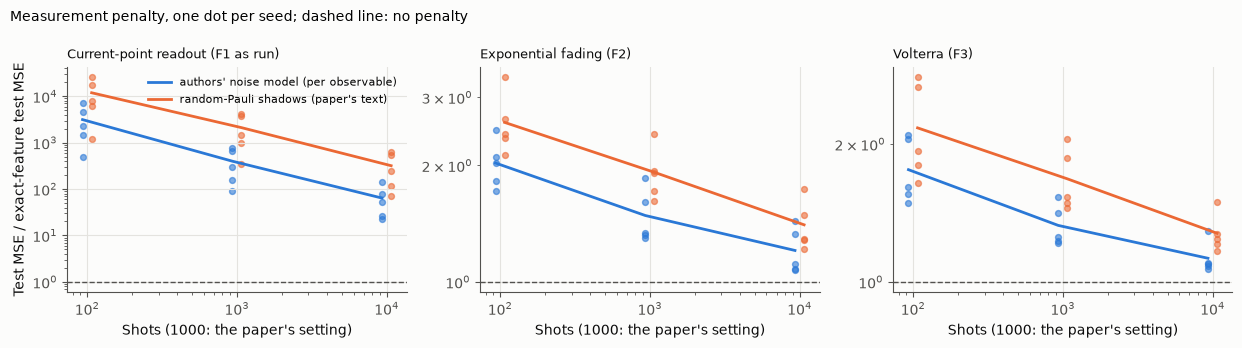

| Task | Noise model | Mean penalty at 100 / 1000 / 10000 shots | Seeds where it falls at both steps |
|---|---|---|---|
| F1 | authors' noise model (per observable) | 3.14e+03 / 399 / 63.9 | 5/5 |
| F1 | random-Pauli shadows (paper's text) | 1.19e+04 / 2.11e+03 / 319 | 5/5 |
| F2 | authors' noise model (per observable) | 2.03 / 1.48 / 1.21 | 5/5 |
| F2 | random-Pauli shadows (paper's text) | 2.58 / 1.92 / 1.4 | 5/5 |
| F3 | authors' noise model (per observable) | 1.76 / 1.33 / 1.13 | 5/5 |
| F3 | random-Pauli shadows (paper's text) | 2.17 / 1.68 / 1.28 | 5/5 |

Ridge chosen on the test set (authors) or on validation data (ours): the same value in 99 of 220 QuaRK fits; otherwise the validation choice raises the test MSE by 0.12% on average, 1.7% at most.


| Reservoir (1000 shots) | F1, normalized test MSE | F2, normalized test MSE | F3, normalized test MSE | Against the paper's size |
|---|---|---|---|---|
| n = 3, R = 3 | 0.0971 ± 0.087 | 0.523 ± 0.087 | 0.719 ± 0.023 | F1 not separated; F2 not separated; F3 the paper's size lower, 5/5 seeds |
| n = 5, R = 3 (paper) | 0.019 ± 0.013 | 0.48 ± 0.035 | 0.508 ± 0.1 | — |
| n = 7, R = 3 | 0.0146 ± 0.008 | 0.39 ± 0.14 | 0.509 ± 0.12 | F1 not separated; F2 not separated; F3 not separated |
| n = 5, R = 1 | 0.0841 ± 0.036 | 0.665 ± 0.025 | 0.72 ± 0.038 | F1 the paper's size lower, 5/5 seeds; F2 the paper's size lower, 5/5 seeds; F3 the paper's size lower, 5/5 seeds |
| n = 5, R = 6 | 0.0131 ± 0.0058 | 0.409 ± 0.067 | 0.451 ± 0.052 | F1 not separated; F2 this size lower, 5/5 seeds (interval contains 0); F3 not separated |

In [10]:
NOISE = {
    "authors' noise model (per observable)": (
        "quark_shots_100",
        "quark",
        "quark_shots_10000",
    ),
    "random-Pauli shadows (paper's text)": (
        "quark_shadows_shots_100",
        "quark_shadows",
        "quark_shadows_shots_10000",
    ),
}
SHOTS = np.array([100, 1000, 10000])
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.5))
penalty_rows = []
for ax, task in zip(axes, TASKS):
    exact = values("quark_exact", task, "mse_test")
    for (name, candidates), color, shift in zip(
        NOISE.items(), ("#2a78d6", "#eb6834"), (0.93, 1.07)
    ):
        ratios = np.array(
            [
                [values(c, task, "mse_test")[s] / exact[s] for s in exact]
                for c in candidates
            ]
        )
        for k, shots in enumerate(SHOTS):
            ax.scatter(
                np.full(ratios.shape[1], shots * shift),
                ratios[k],
                s=18,
                alpha=0.6,
                color=color,
            )
        ax.plot(SHOTS * shift, ratios.mean(axis=1), color=color, lw=2, label=name)
        falling = int(np.sum((ratios[1] < ratios[0]) & (ratios[2] < ratios[1])))
        penalty_rows.append(
            [
                TASKS[task],
                name,
                " / ".join(f"{m:.3g}" for m in ratios.mean(axis=1)),
                f"{falling}/{ratios.shape[1]}",
            ]
        )
    ax.axhline(1, color="#52514e", ls="--", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="Shots (1000: the paper's setting)")
    ax.set_title(TASK_LABELS[task], loc="left", fontsize=9)
axes[0].set_ylabel("Test MSE / exact-feature test MSE")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(
    "Measurement penalty, one dot per seed; dashed line: no penalty",
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
plt.show()
table(
    [
        "Task",
        "Noise model",
        "Mean penalty at 100 / 1000 / 10000 shots",
        "Seeds where it falls at both steps",
    ],
    penalty_rows,
)

reg = STORED["statistics"]["reg_selection"]["QuaRK"]
print(
    f"Ridge chosen on the test set (authors) or on validation data (ours): the same value in {reg['same_reg']} of {reg['fits']} QuaRK fits; "
    f"otherwise the validation choice raises the test MSE by {reg['relative_increase_when_different']['mean']:.2%} on average, {reg['max_relative_increase']:.1%} at most."
)
SIZE_NAMES = ("this size", "the paper's size")
SIZE = {
    "quark_n3": "n = 3, R = 3",
    "quark": "n = 5, R = 3 (paper)",
    "quark_n7": "n = 7, R = 3",
    "quark_r1": "n = 5, R = 1",
    "quark_r6": "n = 5, R = 6",
}
table(
    [
        "Reservoir (1000 shots)",
        *(f"{s}, normalized test MSE" for s in TASKS.values()),
        "Against the paper's size",
    ],
    [
        [
            label,
            *(
                f"{describe(values(c, t).values())['mean']:.3g} ± {describe(values(c, t).values())['std']:.2g}"
                for t in TASKS
            ),
            "—"
            if c == "quark"
            else "; ".join(
                f"{TASKS[t]} {versus(c, 'quark', t, SIZE_NAMES)}" for t in TASKS
            ),
        ]
        for c, label in SIZE.items()
    ],
)

**Observation:** at 1000 shots, measurement multiplies QuaRK's test MSE by 1.48 (F2) and 1.33 (F3) with the authors' model, by 1.92 and 1.68 with shadows, and by hundreds to thousands on F1, which exact features fit almost perfectly; the penalty falls at each tenfold budget, in every seed. The ridge rule changes QuaRK's test MSE by at most 1.7 %. Beyond the paper's reservoir size, only R = 6 on F2 separates, and its interval contains 0.
**Inference:** the figures use the milder noise model, not the shared snapshots of the text.
**Remaining uncertainty:** the shadows estimator is our implementation of the text; the authors' code has none.
**Claim impact:** the paper's numbers are optimistic for the estimator its text describes.

## 11. Photonic assessment: a photonic version of the reservoir matches QuaRK, with or without photon interference

**Scope:** our adaptation, simulated in MerLin; the paper has none. Per sub-reservoir, 3 photons in 14 modes; a fixed random interferometer follows each input step, which sets 14 phases to $\pi(1-10^{-6})\tanh(x_t\Pi)$; the reset is the exact mixture of section 3, with QuaRK's $\lambda_r$; threshold detectors give 105 features, the click rates of single modes and of pairs. Readout, data, split and seeds are QuaRK's; components are ideal. A control makes the photons distinguishable, so they cannot interfere. Details: `docs/photonic_adaptation.md`.

In [11]:
print(
    "Common to every configuration:",
    "; ".join(f"{k.replace('_', ' ')}: {v}" for k, v in DETECTION.items()),
)
table(
    [
        "Configuration",
        "Photons",
        "Modes × sub-reservoirs",
        "Shots per window and sub-reservoir",
        "Simulator",
        "Wall-clock per run (mean)",
    ],
    [
        [
            h["configuration"],
            h["photons"],
            f"{h['modes']} × {h['sub_reservoirs']}",
            h["shots"],
            h["simulator"],
            f"{h['seconds_mean'] / 60:.1f} min",
        ]
        for h in STORED["result_tables"]["hardware"]
    ],
)

PHOTONIC_LIVE = {
    "Photonic, exact": "quark_exact_merlin.json",
    "Photonic, exact, distinguishable photons": "quark_distinguishable_merlin.json",
}
live_photonic = {
    (name, seed): live_run(overlay, seed)
    for name, overlay in PHOTONIC_LIVE.items()
    for seed in LIVE_SEEDS[:2]
}
live_photonic.update(
    {
        k: v
        for k, v in live.items()
        if k[0] == "QuaRK, exact expectations" and k[1] in LIVE_SEEDS[:2]
    }
)
table(
    ["Live, 1,000 windows", *(f"{short}, seeds 12345 / 1" for short in TASKS.values())],
    [
        [
            name,
            *(
                " / ".join(
                    f"{live_value(live_photonic, name, s, t):.3g}"
                    for s in LIVE_SEEDS[:2]
                )
                for t in TASKS
            ),
        ]
        for name in ("QuaRK, exact expectations", *PHOTONIC_LIVE)
    ],
)

Common to every configuration: computation space: FOCK, occupancy_readout=True; detector: ideal threshold detectors (click / no click), no dark counts, no loss; postselection: none; encoding: phases pi (1 - 1e-6) tanh(Pi x_t) on all modes at each step, between copies of one fixed random MZI mesh; measurement: click patterns, reduced to 1- and 2-mode click marginals


| Configuration | Photons | Modes × sub-reservoirs | Shots per window and sub-reservoir | Simulator | Wall-clock per run (mean) |
|---|---|---|---|---|---|
| Photonic, 100 shots | 3 | 14 × 3 | 100 | MerLin simulator (0.4.1), Perceval 1.3.1, cpu, float64 | 10.4 min |
| Photonic, 1000 shots | 3 | 14 × 3 | 1000 | MerLin simulator (0.4.1), Perceval 1.3.1, cpu, float64 | 10.5 min |
| Photonic, 10000 shots | 3 | 14 × 3 | 10000 | MerLin simulator (0.4.1), Perceval 1.3.1, cpu, float64 | 10.1 min |
| Photonic, exact | 3 | 14 × 3 | exact | MerLin simulator (0.4.1), Perceval 1.3.1, cpu, float64 | 10.7 min |
| Photonic, exact, distinguishable photons | 3, distinguishable | 14 × 3 | exact | MerLin simulator (0.4.1), Perceval 1.3.1, cpu, float64 | 11.1 min |

| Live, 1,000 windows | F1, seeds 12345 / 1 | F2, seeds 12345 / 1 | F3, seeds 12345 / 1 |
|---|---|---|---|
| QuaRK, exact expectations | 0.00122 / 0.000122 | 0.491 / 0.268 | 0.493 / 0.476 |
| Photonic, exact | 0.000763 / 0.00362 | 0.414 / 0.371 | 0.416 / 0.511 |
| Photonic, exact, distinguishable photons | 0.000797 / 0.00498 | 0.415 / 0.377 | 0.423 / 0.485 |

At 1,000 windows, the photonic reservoir lands where QuaRK with exact expectations does, and distinguishable photons change little; the full runs below decide.

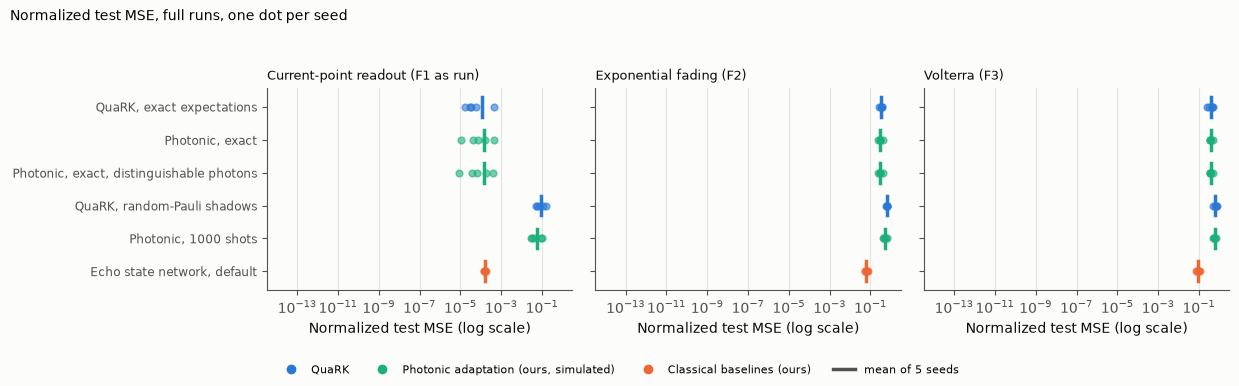

Photonic, exact / QuaRK, exact expectations, ratio of mean normalized test MSE, F1 / F2 / F3: 1.24 / 0.94 / 0.99
Photonic, 1000 shots / QuaRK, random-Pauli shadows, ratio of mean normalized test MSE, F1 / F2 / F3: 0.64 / 0.79 / 0.93
Tolerance fixed before the photonic runs: within a factor 2.


| Photonic | Counterpart | F1 | F2 | F3 |
|---|---|---|---|---|
| Photonic, exact | QuaRK, exact expectations | not separated | not separated | not separated |
| Photonic, exact | Photonic, exact, distinguishable photons | not separated | not separated | not separated |
| Photonic, 1000 shots | QuaRK, random-Pauli shadows | photonic lower, 4/5 seeds (interval contains 0) | photonic lower, 5/5 seeds (interval contains 0) | not separated |
| Photonic, 1000 shots | Echo state network, default | counterpart lower, 5/5 seeds | counterpart lower, 5/5 seeds | counterpart lower, 5/5 seeds |

In [12]:
PHOTONIC = (
    "quark_exact",
    "quark_exact_merlin",
    "quark_distinguishable_merlin",
    "quark_shadows",
    "quark_merlin",
    "esn_default",
)
dot_plot(PHOTONIC, "Normalized test MSE, full runs, one dot per seed")
for a, b in (("quark_exact_merlin", "quark_exact"), ("quark_merlin", "quark_shadows")):
    ratios = [
        describe(values(a, t).values())["mean"]
        / describe(values(b, t).values())["mean"]
        for t in TASKS
    ]
    print(
        f"{LABEL[a]} / {LABEL[b]}, ratio of mean normalized test MSE, F1 / F2 / F3: "
        + " / ".join(f"{x:.2f}" for x in ratios)
    )
print("Tolerance fixed before the photonic runs: within a factor 2.")
table(
    ["Photonic", "Counterpart", *TASKS.values()],
    [
        [
            LABEL[a],
            LABEL[b],
            *(versus(a, b, t, ("photonic", "counterpart")) for t in TASKS),
        ]
        for a, b in (
            ("quark_exact_merlin", "quark_exact"),
            ("quark_exact_merlin", "quark_distinguishable_merlin"),
            ("quark_merlin", "quark_shadows"),
            ("quark_merlin", "esn_default"),
        )
    ],
)

**Observation:** with exact features, the photonic reservoir and QuaRK are not separated on any task, nor are indistinguishable and distinguishable photons. With 1000 shared shots, the photonic version is lower than QuaRK with shadows on F1 and F2 under the rule (4 and 5 of 5 seeds), but both intervals contain 0; F3 is not separated. Every ratio stays within the factor 2 fixed before the runs. Like QuaRK, it stays behind the ESN on the three tasks.
**Inference (ours):** at 3 photons in 14 modes, the accuracy comes from the nonlinear encoding and the fading memory, not from photon interference.
**Remaining uncertainty:** ideal components (no loss, partial distinguishability or detector noise); a classically simulable size; on hardware, the exact reset means reprogramming the circuit at every shot.
**Claim impact:** the paper makes no photonic claim; the adaptation keeps QuaRK's behaviour and its distance to the baselines.

## 12. Conclusion

1. **What reproduced:** the authors' run, exactly (sections 4 and 7); over 5 seeds, interpolation, the decrease with N and the task ranking (section 7b).
2. **What did not reproduce:** the $1/\sqrt{N}$ shape on F2 and F3, whose slopes are near −0.1 (section 7b).
3. **What remains unresolved:** high-dimensional inputs, which the projection compresses, as the paper motivates; how tight the bound can be made (section 7b).
4. **What was not attempted:** a re-check of the proof of Theorem 2, hardware runs, the authors' later experiments.
5. **Reproduction verdict:** the experiments reproduce exactly, and the learning claims hold only in part: interpolation and the ranking come from the readout and the labels (sections 7b and 9). Every classical baseline has a lower test error than QuaRK (section 8); shot noise inflates QuaRK's error, and the paper's figures use the milder noise model (section 10).
6. **Photonic verdict:** a photonic version of the reservoir matches QuaRK, with or without photon interference, with ideal components (section 11).

| Outcome | Status | Sections |
|---|---|---|
| The software executes | yes: this notebook runs end to end, and the 100 stored runs completed | 6, 7 |
| The method solves the tasks | in part: normalized test MSE 0.02 (F1), 0.48 (F2), 0.51 (F3) | 8 |
| The paper's metric reproduces | yes, exactly at the authors' seed | 7 |
| The explanation survives the controls | in part: interpolation and the ranking hold for classical models too | 7b, 9 |
| The method beats a fair baseline | no | 8 |

**Limitations:** live cells at 1,000 windows and 3 seeds, full results from stored runs; synthetic data with 3 input dimensions; seeds 1–4 newly drawn; numpy simulation, checked against the authors' features; shadows estimator ours; bound evaluated, not re-proved; ideal photonic components; every model classically simulable at these sizes, so no claim about quantum cost or speed is tested.

In [13]:
print(f"Notebook run time: {(time.perf_counter() - START) / 60:.1f} min")

Notebook run time: 2.6 min
